In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

### Load the data

In [2]:
data = pd.read_csv("credit_risk_dataset.csv")

In [4]:
data.shape

(32581, 12)

In [5]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0+ MB


### Null values

In [6]:
data.isnull().sum()

person_age                       0
person_income                    0
person_home_ownership            0
person_emp_length              895
loan_intent                      0
loan_grade                       0
loan_amnt                        0
loan_int_rate                 3116
loan_status                      0
loan_percent_income              0
cb_person_default_on_file        0
cb_person_cred_hist_length       0
dtype: int64

In [7]:
data['loan_status'].value_counts()

loan_status
0    25473
1     7108
Name: count, dtype: int64

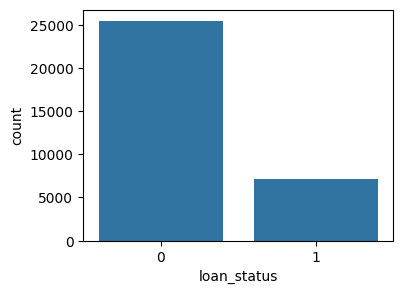

In [8]:
## Class Imbalanced
plt.figure(figsize=(4,3))
sns.countplot(x='loan_status', data=data)
plt.show()

In [9]:
data.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.000000,3.258100e+04,31686.000000,32581.000000,29465.000000,32581.000000,32581.000000,32581.000000
mean,27.734600,6.607485e+04,4.789686,9589.371106,11.011695,0.218164,0.170203,5.804211
std,6.348078,6.198312e+04,4.142630,6322.086646,3.240459,0.413006,0.106782,4.055001
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.920000e+04,7.000000,12200.000000,13.470000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


In [10]:
numeric_cols = data.select_dtypes(include=np.number).columns

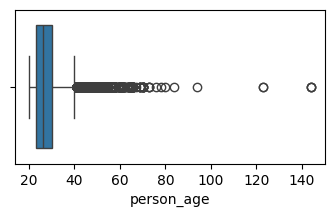

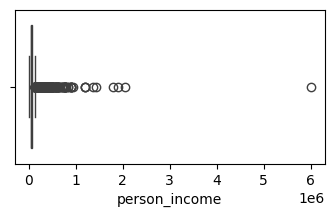

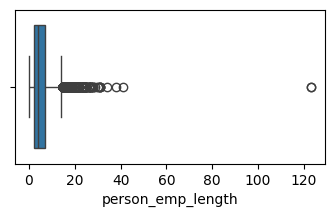

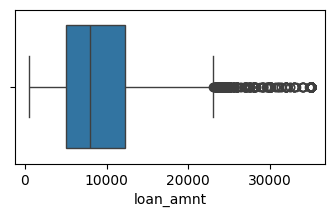

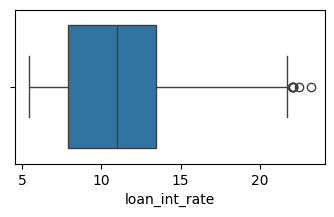

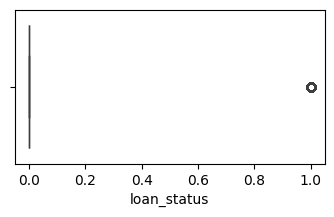

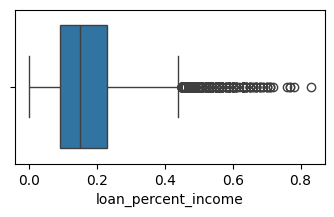

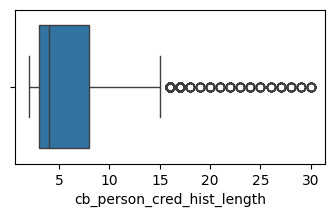

In [11]:
for i in numeric_cols:
    plt.figure(figsize=(4,2))
    sns.boxplot(x=data[i])
    plt.show()

In [12]:
(data['person_age'] > 100).sum()

np.int64(5)

In [13]:
(data['person_emp_length'] > 60).sum()

np.int64(2)

In [14]:
data.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


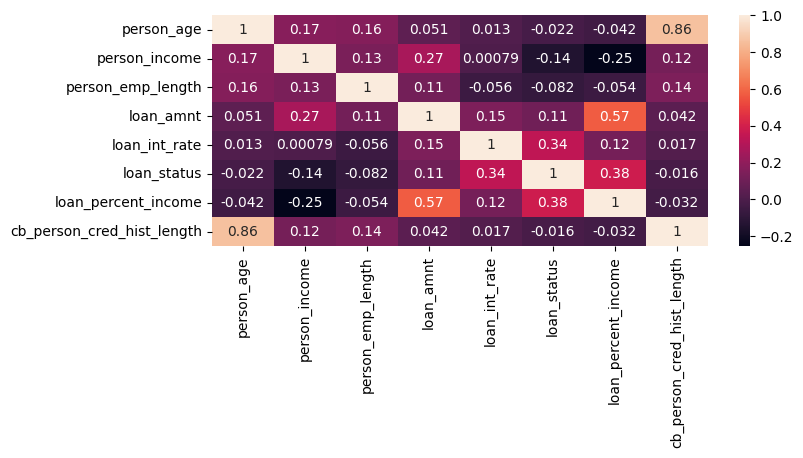

In [15]:
plt.figure(figsize=(8,3))
sns.heatmap(data.corr(numeric_only=True), annot=True)
plt.show()

#### Removing cb_person_cred_hist_length column as it has high correlation with age

In [16]:
data.drop(columns=['cb_person_cred_hist_length'], inplace=True)

In [17]:
data.columns

Index(['person_age', 'person_income', 'person_home_ownership',
       'person_emp_length', 'loan_intent', 'loan_grade', 'loan_amnt',
       'loan_int_rate', 'loan_status', 'loan_percent_income',
       'cb_person_default_on_file'],
      dtype='object')

### Data validation and outlier handeling

#### 1) Dropping duplicates

In [18]:
print(f"Rows before dropping duplicates {data.shape[0]}")
data.drop_duplicates(inplace=True)
print(f"Rows after dropping duplicates {data.shape[0]}")

Rows before dropping duplicates 32581
Rows after dropping duplicates 31993


#### Remove ages below 18 or above 100

In [19]:
data = data[~((data['person_age'] < 18) | (data['person_age'] >= 100))]

#### Remove employment length greater than age or extreme outliers (>60)

In [20]:
data = data[~((data['person_emp_length'] > data['person_age']) | (data['person_emp_length'] > 60))]

### Seperating X and Y

In [21]:
X = data.drop(columns=['loan_status'])
y = data['loan_status']

### Splitting into train and test

In [22]:
from sklearn.model_selection import train_test_split

In [23]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

In [24]:
numeric_cols = X.select_dtypes(include=np.number).columns

In [25]:
numeric_cols
categorical_cols = ['person_home_ownership', 'loan_intent', 'loan_grade', 'cb_person_default_on_file']

In [26]:
X.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_percent_income,cb_person_default_on_file
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0.10,N
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,0.57,N
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,0.53,N
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,0.55,Y
5,21,9900,OWN,2.0,VENTURE,A,2500,7.14,0.25,N


### Handeling class imbalanced

In [27]:
# 1 --> Yes
# 0 --> No (Most)
y_train.value_counts()

loan_status
0    19985
1     5603
Name: count, dtype: int64

In [28]:
neg, pos = np.bincount(y_train)
scale_weights = neg / pos

### Data Preprocessing

In [29]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

In [30]:
preprocessing_lr = ColumnTransformer(
    transformers=[
        ('num', Pipeline(
            steps=[
                ('impute', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler())
            ]
        ), numeric_cols),
        ('cat', Pipeline(
            steps=[
                ('impute', SimpleImputer(strategy='constant', fill_value='Missing')),
                ('onehot', OneHotEncoder(handle_unknown='ignore'))
            ]
        ), categorical_cols)
    ]
)

In [31]:
preprocessing_xg = ColumnTransformer(
    transformers=[
        ('num', Pipeline(
            steps=[
                ('impute', SimpleImputer(strategy='median')),
            ]
        ), numeric_cols),
        ('cat', Pipeline(
            steps=[
                ('impute', SimpleImputer(strategy='constant', fill_value='Missing')),
                ('onehot', OneHotEncoder(handle_unknown='ignore'))
            ]
        ), categorical_cols)
    ]
)

In [32]:
from sklearn.model_selection import StratifiedKFold, cross_validate

In [33]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [34]:
scoring = {
    'roc_auc': 'roc_auc',
    'precision': 'precision',
    'recall': 'recall',
    'f1': 'f1'
}

In [35]:
from sklearn.linear_model import LogisticRegression

In [36]:
lr_model = Pipeline(
    steps=[
        ('preprocessing', preprocessing_lr),
        ('lr_model', LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced'))
    ]
)

In [37]:
from xgboost import XGBClassifier

In [38]:
xg_model = Pipeline(
    steps=[
        ('preprocessing', preprocessing_xg),
        ('xg_model', XGBClassifier(
            n_estimator = 2000,
            max_depth = 5,
            learning_rate = 0.1,
            scale_pos_weight = scale_weights
        ))
    ]
)

In [39]:
for name, pipe in [('LogisticRegression', lr_model), ('XGBoost', xg_model)]:
    cv_result = cross_validate(pipe, X_train, y_train, scoring=scoring, cv=cv, n_jobs=-1)
    print(name)
    print(f'ROC-AUC: {cv_result['test_roc_auc']}')
    print(f'ROC-AUC (mean): {cv_result['test_roc_auc'].mean()}')
    print(f"Test precision: {cv_result['test_precision']}")
    print(f"Test precision (mean): {cv_result['test_precision'].mean()}")
    print(f"Test recall: {cv_result['test_recall']}")
    print(f"Test recall (mean): {cv_result['test_recall'].mean()}")
    print(f"Test F1: {cv_result['test_f1']}")
    print(f"Test F1 (mean): {cv_result['test_f1'].mean()}")
    print()

LogisticRegression
ROC-AUC: [0.86941477 0.87460511 0.86851624 0.86993526 0.86443806]
ROC-AUC (mean): 0.8693818887885169
Test precision: [0.52700297 0.54878807 0.54671717 0.55424837 0.55181347]
Test precision (mean): 0.5457140087428642
Test recall: [0.79214987 0.78768956 0.77252453 0.75714286 0.76071429]
Test recall (mean): 0.7740442207212948
Test F1: [0.63292944 0.64688645 0.64029575 0.64       0.63963964]
Test F1 (mean): 0.6399502544121297

XGBoost
ROC-AUC: [0.94190179 0.9399293  0.94115859 0.94245662 0.93677803]
ROC-AUC (mean): 0.9404448653569955
Test precision: [0.78291194 0.79032258 0.79782412 0.79010082 0.80329369]
Test precision (mean): 0.7928906305851108
Test recall: [0.80107047 0.7867975  0.78501338 0.76964286 0.78392857]
Test recall (mean): 0.7852905569007265
Test F1: [0.79188713 0.7885561  0.79136691 0.77973768 0.793493  ]
Test F1 (mean): 0.7890081609621363



In [40]:
cv_result

{'fit_time': array([0.87049055, 0.83636427, 0.87122703, 2.26264501, 2.28108859]),
 'score_time': array([0.15378165, 0.13145161, 0.16097641, 0.3589642 , 0.3819983 ]),
 'test_roc_auc': array([0.94190179, 0.9399293 , 0.94115859, 0.94245662, 0.93677803]),
 'test_precision': array([0.78291194, 0.79032258, 0.79782412, 0.79010082, 0.80329369]),
 'test_recall': array([0.80107047, 0.7867975 , 0.78501338, 0.76964286, 0.78392857]),
 'test_f1': array([0.79188713, 0.7885561 , 0.79136691, 0.77973768, 0.793493  ])}

### Baseline model

In [41]:
baseline_model = Pipeline(
    steps=[
        ('preprocessor', preprocessing_lr),
        ('logistic_classifier', LogisticRegression(class_weight='balanced'))
    ]
)

In [42]:
from sklearn.metrics import accuracy_score, recall_score, f1_score, confusion_matrix, precision_score, classification_report, precision_recall_curve

In [43]:

# # Function to evaluate a classification model
# def eval_model(model_name, model, X_test, y_test):
#     # Make predictions
#     y_pred = model.predict(X_test)
#     y_pred_prob = model.predict_proba(X_test)[:, 1]

#     # Calculate evaluation metrics
#     accuracy = accuracy_score(y_test, y_pred)
#     precision = precision_score(y_test, y_pred, zero_division=0)
#     recall = recall_score(y_test, y_pred, zero_division=0)
#     f1 = f1_score(y_test, y_pred, zero_division=0)

#     print(f"{model_name} Evaluation")
#     print(f"Accuracy: {accuracy:.4f}")
#     print(f"Precision: {precision:.4f}")
#     print(f"Recall: {recall:.4f}")
#     print(f"F1 Score: {f1:.4f}")
#     print()

#     # Classification report
#     class_report = classification_report(
#         y_test, y_pred, zero_division=0
#     )
#     print(f"{model_name} Classification Report:")
#     print(class_report)

#     # Plot confusion matrix
#     plt.figure(figsize=(5, 3))
#     sns.heatmap(
#         confusion_matrix(y_test, y_pred),
#         annot=True,
#         fmt="d",
#         cmap="Blues"
#     )
#     plt.title(f"{model_name} Confusion Matrix")
#     plt.xlabel("Predicted Values")
#     plt.ylabel("Actual Values")
#     plt.show()

#     # Plot Precision-Recall curve
#     precisions, recalls, thresholds = precision_recall_curve(
#         y_test, y_pred_prob
#     )

#     plt.figure(figsize=(5, 3))
#     plt.plot(recalls, precisions)
#     plt.xlabel("Recall")
#     plt.ylabel("Precision")
#     plt.title(f"{model_name} Precision-Recall Curve")
#     plt.show()


In [44]:
xg_model_tuning = Pipeline(
    steps=[
        ('preprocessing', preprocessing_xg),
        ('xg_model', XGBClassifier(
            n_estimator = 2000,
            max_depth = 5,
            learning_rate = 0.1,
            scale_pos_weight = scale_weights
        ))
    ]
)

In [45]:
xg_model_tuning.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('xg_model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['person_age','person_income','person_home_ownership',...,'loan_int_rate', 'loan_percent_income','cb_person_default_on_file']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of `

In [46]:
y_pred = xg_model_tuning.predict(X_test)

In [47]:
res = pd.DataFrame({
    'Actual': y_test,
    'Prediction': y_pred
})

In [48]:
baseline_model.fit(X_test, y_pred)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('logistic_classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['person_age','person_income','person_home_ownership',...,'loan_int_rate', 'loan_percent_income','cb_person_default_on_file']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (de

In [49]:
# Function to evaluate a classification model
def eval_model(model_name, model, X_test, y_test, threshold=None):
    # Make predictions
    y_pred_prob = model.predict_proba(X_test)[:, 1]

    if threshold:
        y_pred = (y_pred_prob > threshold).astype(int)
    else:
        y_pred = model.predict(X_test)

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)

    print(f"{model_name} Evaluation")
    # print(f"Best threshold: {best_threshold}")
    print(f"Accuracy: {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1 Score: {f1:.4f}")
    print()

    # Classification report
    class_report = classification_report(
        y_test, y_pred, zero_division=0
    )
    print(f"{model_name} Classification Report:")
    print(class_report)

    # Plot confusion matrix
    plt.figure(figsize=(5, 3))
    sns.heatmap(
        confusion_matrix(y_test, y_pred),
        annot=True,
        fmt="d",
        cmap="Blues"
    )
    plt.title(f"{model_name} Confusion Matrix")
    plt.xlabel("Predicted Values")
    plt.ylabel("Actual Values")
    plt.show()

    # Plot Precision-Recall curve
    precisions, recalls, thresholds = precision_recall_curve(
        y_test, y_pred_prob
    )

    plt.figure(figsize=(5, 3))
    plt.plot(recalls, precisions)
    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.title(f"{model_name} Precision-Recall Curve")
    plt.show()

XG Boost Evaluation
Accuracy: 0.9112
Precision: 0.8029
Recall: 0.7880
F1 Score: 0.7954

XG Boost Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.95      0.94      4997
           1       0.80      0.79      0.80      1401

    accuracy                           0.91      6398
   macro avg       0.87      0.87      0.87      6398
weighted avg       0.91      0.91      0.91      6398



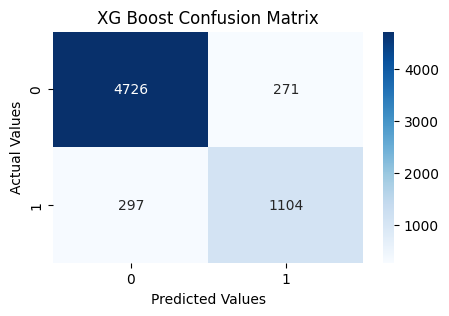

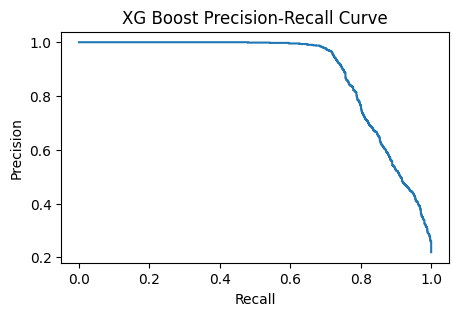

In [50]:
eval_model('XG Boost', xg_model_tuning, X_test, y_test)

### Hyper-parameter Tuning

In [51]:
from sklearn.model_selection import RandomizedSearchCV

In [52]:
parameter_dist = {
    "xg_model__n_estimators": [100, 500, 100, 1500, 2000],
    "xg_model__max_depth": [3, 4, 6, 8],
    "xg_model__gamma": [0, 0.1, 1, 5],
    "xg_model__learning_rate": [0.01, 0.05, 0.1, 0.3],
    "xg_model__colsample_bytree": [0.6, 0.8, 1.0],
    "xg_model__subsample": [0.6, 0.8, 1.0],
    "xg_model__min_child_weight": [1, 3, 5, 10]
}

In [53]:
rscv = RandomizedSearchCV(
    estimator=xg_model_tuning,
    param_distributions=parameter_dist,
    n_iter=150,
    cv=cv,
    scoring='average_precision',
    n_jobs=-1,
    verbose=1
)

In [54]:
# rscv.fit(X_train, y_test)

In [55]:
# Best parameters are:
# {
#     'xg_model__subsample': 1.0,
#     'xg_model__n_estimators': 500,
#     'xg_model__min_child_weight': 5,
#     'xg_model__max_depth': 6,
#     'xg_model__learning_rate': 0.1,
#     'xg_model__gamma': 0,
#     'xg_model__colsample_bytree': 0.8
# }

In [56]:
xg = Pipeline(
    steps=[
        ('preprocessing', preprocessing_xg),
        ('xg_model', XGBClassifier(
            n_estimator = 500,
            max_depth = 6,
            learning_rate = 0.1,
            scale_pos_weight = scale_weights,
            gamma = 0,
            colsample_bytree = 0.8,
            subsample = 1.0,
            min_child_weight = 5
        ))
    ]
)

In [57]:
xg.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('xg_model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['person_age','person_income','person_home_ownership',...,'loan_int_rate', 'loan_percent_income','cb_person_default_on_file']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of `

XG boost Evaluation
Accuracy: 0.9112
Precision: 0.8029
Recall: 0.7880
F1 Score: 0.7954

XG boost Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.95      0.94      4997
           1       0.80      0.79      0.80      1401

    accuracy                           0.91      6398
   macro avg       0.87      0.87      0.87      6398
weighted avg       0.91      0.91      0.91      6398



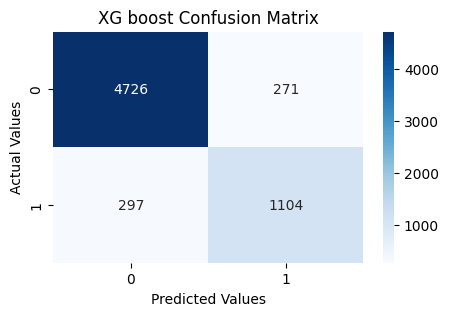

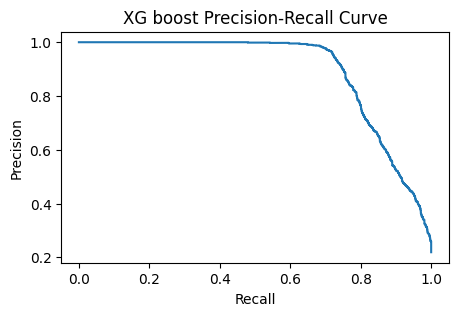

In [58]:
eval_model('XG boost', xg_model_tuning, X_test, y_test)

XG boost Evaluation
Accuracy: 0.9187
Precision: 0.8345
Recall: 0.7844
F1 Score: 0.8087

XG boost Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.96      0.95      4997
           1       0.83      0.78      0.81      1401

    accuracy                           0.92      6398
   macro avg       0.89      0.87      0.88      6398
weighted avg       0.92      0.92      0.92      6398



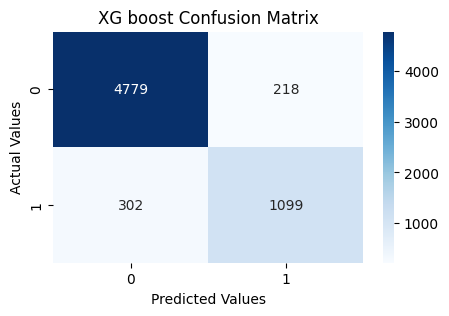

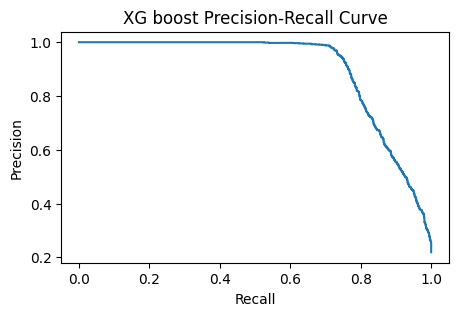

In [59]:
eval_model('XG boost', xg, X_test, y_test)

### Optimizing the classification threshold

In [60]:
# Get the probabilities of class 1 from XG boost
prob = xg.predict_proba(X_test)[:, 1]

In [61]:
prob

array([0.0138147 , 0.00160911, 0.04247601, ..., 0.00647583, 0.04359019,
       0.17523025], shape=(6398,), dtype=float32)

In [62]:
# For each threshold, calculate precision and recall
precisions, recall, threshold = precision_recall_curve(y_test, prob)

In [63]:
# Calculate f1 score for ecah threshold
f1 = 2 * (precisions - recall) / (precisions + recall + 1e-9)

In [64]:
# Find the threshold with the highest F1 score
best_idx = np.argmax(f1[:-1])

In [65]:
best_threshold = threshold[best_idx]
best_f1 = f1[best_idx]

In [114]:
best_threshold

np.float32(0.9996642)

XG boost with threshold Evaluation
Accuracy: 0.9187
Precision: 0.8345
Recall: 0.7844
F1 Score: 0.8087

XG boost with threshold Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.96      0.95      4997
           1       0.83      0.78      0.81      1401

    accuracy                           0.92      6398
   macro avg       0.89      0.87      0.88      6398
weighted avg       0.92      0.92      0.92      6398



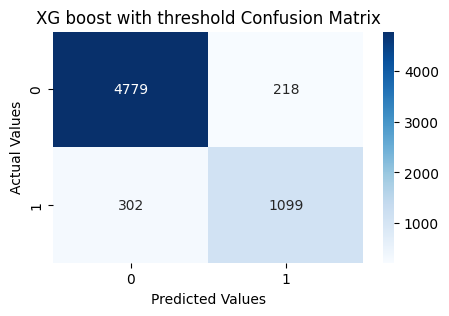

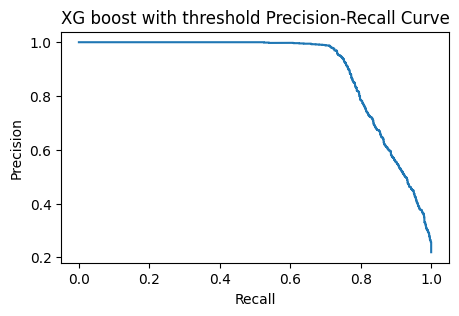

In [66]:
# Evaluate the XG boost model using that threshold
eval_model('XG boost with threshold', xg, X_test, y_test)

### Probability calibration

In [67]:
# Sometimes model's probability does not mean what it says
# For example, 30% risk should truly means 305 chance
# We check this with the calibration plot

In [68]:
"""
Methods through which we can fix the poorly calibrated model.
1. Platt scaling (Sigmoid calibration)
2. Isotonic Regression
3. Temperature Scaling
"""

'\nMethods through which we can fix the poorly calibrated model.\n1. Platt scaling (Sigmoid calibration)\n2. Isotonic Regression\n3. Temperature Scaling\n'

In [69]:
# 1. Calibrate XG boost model
from sklearn.calibration import CalibratedClassifierCV, calibration_curve

In [70]:
calibrated_model = CalibratedClassifierCV(
    estimator=xg,
    cv=5,
    method='sigmoid'
)

In [71]:
calibrated_model.fit(X_test, y_test)

,"estimator estimator: estimator instance, default=NoneThe classifier whose output need to be calibrated to provide moreaccurate `predict_proba` outputs. The default classifier isa :class:`~sklearn.svm.LinearSVC`... versionadded:: 1.2","Pipeline(step...=None, ...))])"
,"cv cv: int, cross-validation generator, or iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross-validation,- integer, to specify the number of folds,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if ``y`` is binary or multiclass,:class:`~sklearn.model_selection.StratifiedKFold` is used. If ``y`` isneither binary nor multiclass, :class:`~sklearn.model_selection.KFold`is used.Refer to the :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"method method: {'sigmoid', 'isotonic', 'temperature'}, default='sigmoid'The method to use for calibration. Can be:- 'sigmoid', which corresponds to Platt's method (i.e. a binary logistic regression model).- 'isotonic', which is a non-parametric approach.- 'temperature', temperature scaling.Sigmoid and isotonic calibration methods natively support only binaryclassifiers and extend to multi-class classification using a One-vs-Rest (OvR)strategy with post-hoc renormalization, i.e., adjusting the probabilities aftercalibration to ensure they sum up to 1.In contrast, temperature scaling naturally supports multi-class calibration byapplying `softmax(classifier_logits/T)` with a value of `T` (temperature)that optimizes the log loss.For very uncalibrated classifiers on very imbalanced datasets, sigmoidcalibration might be preferred because it fits an additional interceptparameter. This helps shift decision boundaries appropriately when theclassifier being calibrated is biased towards the majority class.Isotonic calibration is not recommended when the number of calibration samplesis too low ``(≪1000)`` since it then tends to overfit... versionchanged:: 1.8 Added option 'temperature'.",'sigmoid'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors.Base estimator clones are fitted in parallel across cross-validationiterations.See :term:`Glossary <n_jobs>` for more details... versionadded:: 0.24",None
,"ensemble ensemble: bool, or ""auto"", default=""auto""Determines how the calibrator is fitted.""auto"" will use `False` if the `estimator` is a:class:`~sklearn.frozen.FrozenEstimator`, and `True` otherwise.If `True`, the `estimator` is fitted using training data, andcalibrated using testing data, for each `cv` fold. The final estimatoris an ensemble of `n_cv` fitted classifier and calibrator pairs, where`n_cv` is the number of cross-validation folds. The output is theaverage predicted probabilities of all pairs.If `False`, `cv` is used to compute unbiased predictions, via:func:`~sklearn.model_selection.cross_val_predict`, which are thenused for calibration. At prediction time, the classifier used is the`estimator` trained on all the data.Note that this method is also internally implemented in:mod:`sklearn.svm` estimators with the `probabilities=True` parameter... versionadded:: 0.24.. versionchanged:: 1.6 `""auto""` option is added and is the default.",'auto'
Name,Type,Value
"calibrated_classifiers_ calibrated_classifiers_: list (len() equal to cv or 1 if `ensemble=False`)The list of classifier and calibrator pairs.- When `ensemble=True`, `n_cv` fitted `estimator` and calibrator pairs. `n_cv` is the number of cross-validation folds.- When `ensemble=False`, the `estimator`, fitted on all the data, and fitted calibrator... versionchanged:: 0.24 Single calibrated classifier case when `ensemble=False`.",list,"[<sklearn.cali...001CC7A3A5BE0>, <

In [72]:
# Get probabilities
uncalibrated = xg.predict_proba(X_test)[:, 1]
calibrated = calibrated_model.predict_proba(X_test)[:, 1]

In [73]:
# Create calibration curve
actual_uncal, predicted_uncal = calibration_curve(y_test, uncalibrated, n_bins=10)
actual_cal, predicted_cal = calibration_curve(y_test, calibrated, n_bins=10)

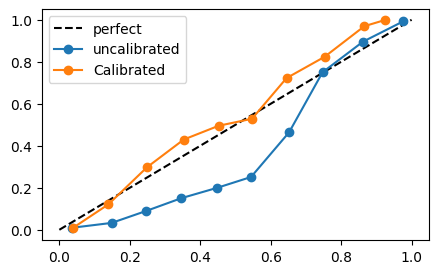

In [74]:
# Plot
plt.figure(figsize=(5,3))
plt.plot([0,1], [0,1], "k--", label="perfect")
plt.plot(
    predicted_uncal,
    actual_uncal,
    "o-",
    label = "uncalibrated"
)

plt.plot(
    predicted_cal,
    actual_cal,
    "o-",
    label = "Calibrated"
)

plt.legend()
plt.show()

Calibrated XG boost model Evaluation
Accuracy: 0.9448
Precision: 0.9418
Recall: 0.7973
F1 Score: 0.8635

Calibrated XG boost model Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.99      0.97      4997
           1       0.94      0.80      0.86      1401

    accuracy                           0.94      6398
   macro avg       0.94      0.89      0.91      6398
weighted avg       0.94      0.94      0.94      6398



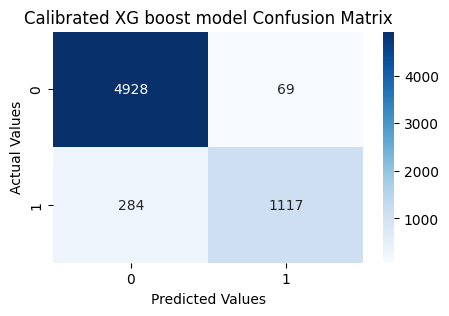

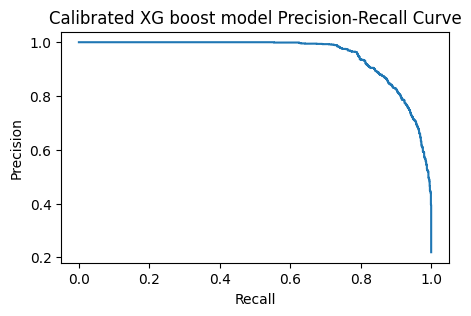

In [75]:
eval_model('Calibrated XG boost model', calibrated_model, X_test, y_test)

### SHAP interpretion - Global and Local

In [76]:
# SHAP helps us to understand why the model makes a dicision
# It is a way of explaining a 'black box' model

In [77]:
import shap

In [78]:
# Get the trainer classifier xg boost model out of the pipeline
xgb_classifier = xg.named_steps['xg_model']

In [79]:
# Transform the X_test using the same preprocessing used for training

In [80]:
X_trained_transform = xg.named_steps['preprocessing'].transform(X_test)

In [81]:
# Get features name after one hot encoding
features_names = xg.named_steps['preprocessing'].get_feature_names_out()

In [82]:
# Convert to a dataframe for cleaner SHAP plot
X_test_df = pd.DataFrame(X_trained_transform, columns=features_names)

In [83]:
# Create a SHAP explainer
explainer = shap.TreeExplainer(xgb_classifier)

In [84]:
shap_values = explainer.shap_values(X_test_df)

In [85]:
shap_values

array([[ 4.10367660e-02, -1.23466063e+00, -1.92970008e-01, ...,
        -1.03542553e-02, -1.19274119e-02, -4.07275802e-05],
       [ 2.28594188e-02, -1.07734203e+00, -1.99576303e-01, ...,
        -1.25554437e-02, -2.09207158e-03, -4.07275802e-05],
       [ 1.45658003e-02,  2.57879607e-02,  7.19869956e-02, ...,
        -1.12469830e-02, -3.00585502e-03, -2.55562172e-05],
       ...,
       [ 4.63347845e-02, -3.47742252e-02,  6.65728599e-02, ...,
        -7.54257152e-03, -2.46443413e-03, -5.93360710e-05],
       [ 8.11279844e-03, -9.40485299e-02,  9.51461568e-02, ...,
        -1.01017887e-02, -2.88253021e-03, -2.55562172e-05],
       [-2.56129019e-02, -5.78769028e-01, -1.10600926e-01, ...,
        -1.20042181e-02,  3.41901146e-02,  3.70085072e-05]],
      shape=(6398, 25), dtype=float32)

### Global explaination

In [86]:
# It shows which features matters most for prediction

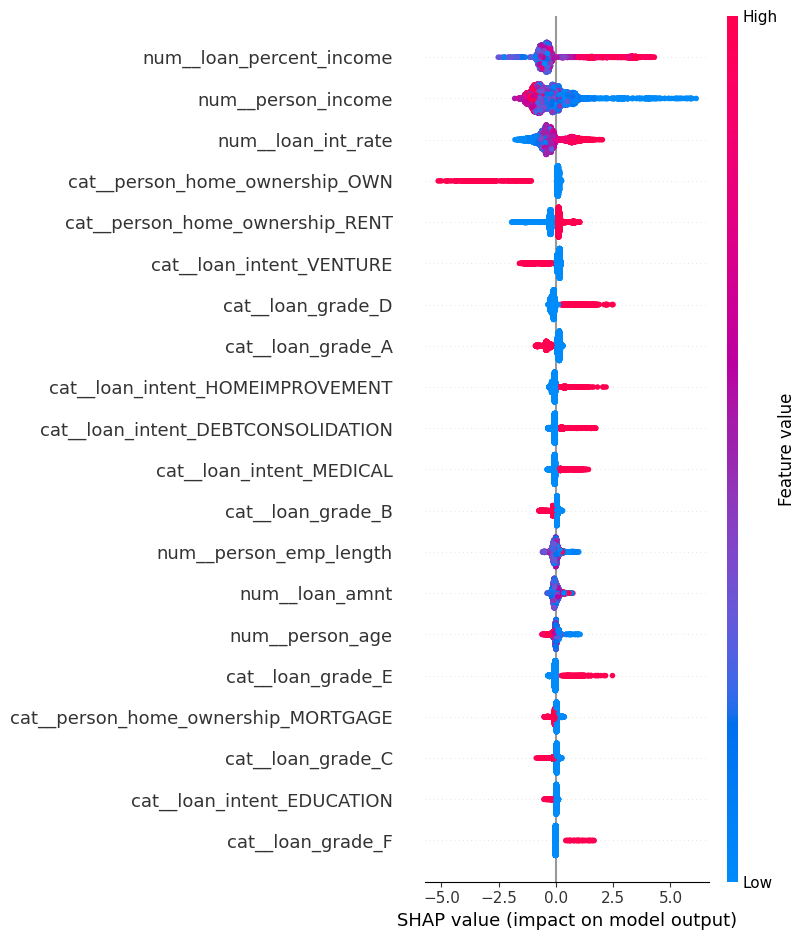

In [87]:
shap.summary_plot(shap_values, X_test_df)

### Local explaination

In [88]:
# This shows why one specific applicant got their score

In [89]:
# Pick one row to explain
row_index = 5

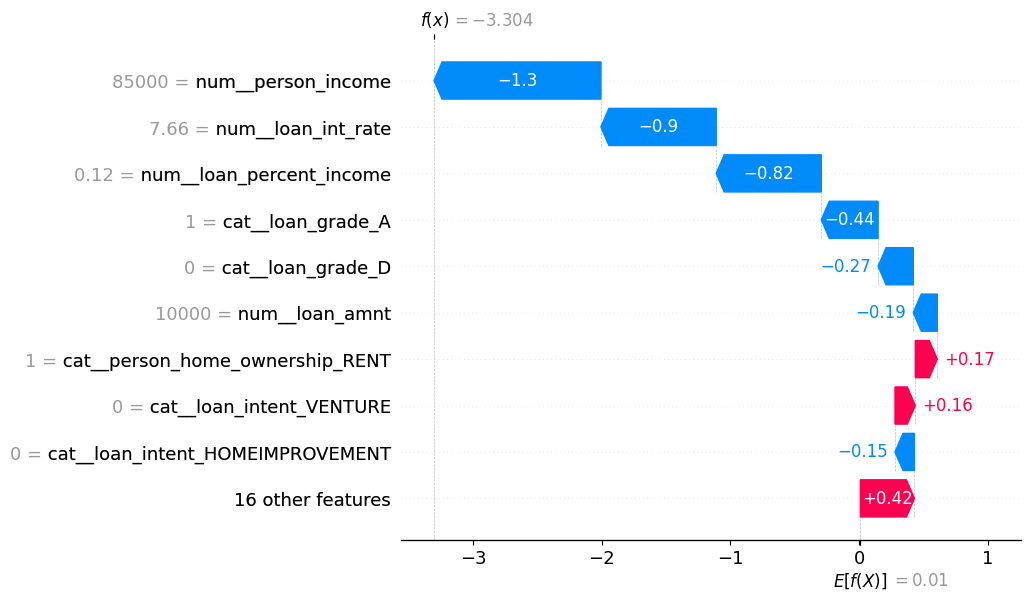

In [90]:
shap.plots.waterfall(
    shap.Explanation(
        values = shap_values[row_index],
        base_values = explainer.expected_value,
        data = X_test_df.iloc[row_index],
        feature_names = features_names
    )
)

### Analyzing false positive and false negative

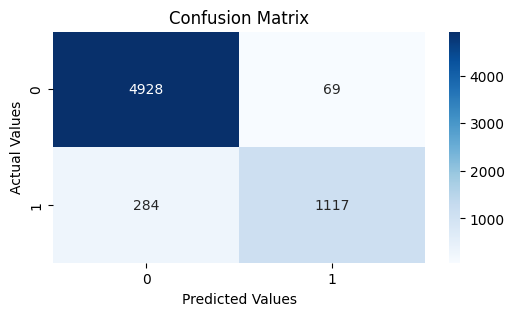

In [91]:
plt.figure(figsize=(6,3))
sns.heatmap(
        confusion_matrix(y_test, calibrated_model.predict(X_test)),
        annot=True,
        fmt="d",
        cmap="Blues"
)
plt.title(f"Confusion Matrix")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.show()

### Save the model

In [92]:
import joblib

In [93]:
joblib.dump(calibrated_model, filename="credit_risk_model.pkl")

['credit_risk_model.pkl']

In [155]:
X.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_percent_income,cb_person_default_on_file
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0.10,N
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,0.57,N
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,0.53,N
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,0.55,Y
5,21,9900,OWN,2.0,VENTURE,A,2500,7.14,0.25,N


In [158]:
X['cb_person_default_on_file'].unique()

array(['N', 'Y'], dtype=object)

In [178]:
data[data['loan_status'] == 1].sample(10)

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file
7705,22,30000,RENT,4.0,DEBTCONSOLIDATION,D,7000,16.49,1,0.23,Y
18162,30,102213,RENT,3.0,MEDICAL,D,25000,15.70,1,0.21,N
62,26,263000,MORTGAGE,0.0,EDUCATION,B,10000,NaN,1,0.04,N
10081,24,28000,RENT,1.0,MEDICAL,A,9500,5.99,1,0.34,N
29141,43,74000,RENT,2.0,DEBTCONSOLIDATION,E,30600,18.79,1,0.41,N
5390,25,69000,RENT,5.0,HOMEIMPROVEMENT,A,8500,6.92,1,0.12,N
16902,25,57500,RENT,4.0,EDUCATION,C,6000,11.28,1,0.10,N
21182,29,67027,RENT,NaN,MEDICAL,A,5000,7.51,1,0.06,N
10856,26,64000,MORTGAGE,5.0,DEBTCONSOLIDATION,D,7000,15.95,1,0.11,N
2669,26,44000,RENT,0.0,HOMEIMPROVEMENT,A,3000,7.49,1,0.07,N


In [175]:
data.iloc[26766]

person_age                         34
person_income                  122400
person_home_ownership        MORTGAGE
person_emp_length                 5.0
loan_intent                   MEDICAL
loan_grade                          B
loan_amnt                        6800
loan_int_rate                   10.65
loan_status                         0
loan_percent_income              0.06
cb_person_default_on_file           N
Name: 27104, dtype: object